In [2]:
import pandas as pd
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
df.describe()


Dataset size: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Summary statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [4]:
gender_analysis = df.groupby("Gender").agg(
    Number_of_Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

gender_analysis

,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score
Gender,,,,
Female,112,38.10,59.25,51.53
Male,88,39.81,62.23,48.51


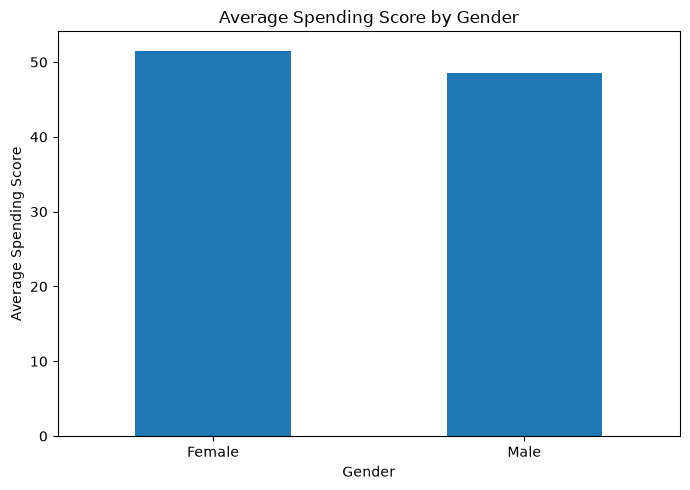

In [5]:
import matplotlib.pyplot as plt

gender_analysis["Average_Spending_Score"].plot(
    kind="bar",
    figsize=(7, 5),
    title="Average Spending Score by Gender"
)

plt.xlabel("Gender")
plt.ylabel("Average Spending Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

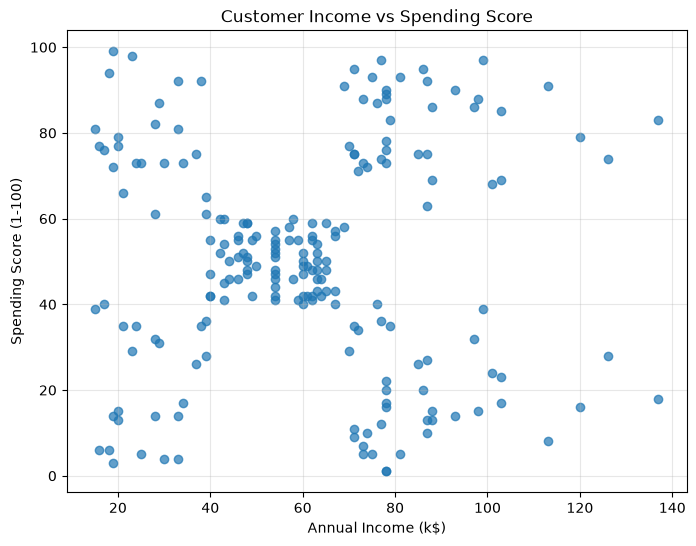

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    alpha=0.7
)

plt.title("Customer Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True, alpha=0.3)

plt.show()

In [7]:
def customer_segment(row):
    income = row["Annual Income (k$)"]
    spending = row["Spending Score (1-100)"]

    if income >= 70 and spending >= 60:
        return "High Income, High Spending"
    elif income >= 70 and spending < 40:
        return "High Income, Low Spending"
    elif income < 40 and spending >= 60:
        return "Low Income, High Spending"
    elif income < 40 and spending < 40:
        return "Low Income, Low Spending"
    else:
        return "Average or Mixed"

df["Customer Segment"] = df.apply(customer_segment, axis=1)

df["Customer Segment"].value_counts()

Customer Segment
Average or Mixed              80
High Income, High Spending    38
High Income, Low Spending     37
Low Income, High Spending     23
Low Income, Low Spending      22
Name: count, dtype: int64

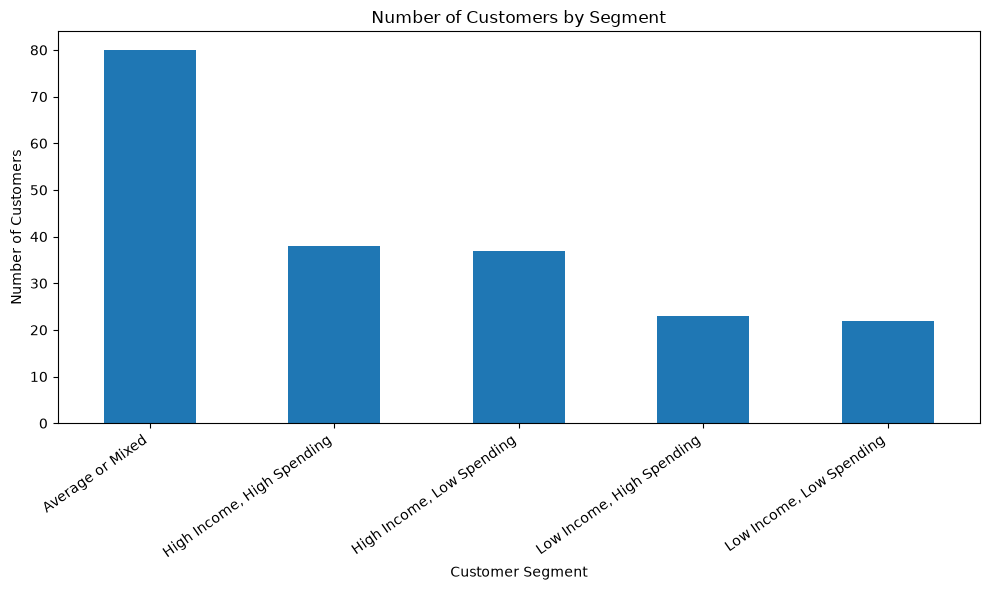

In [8]:
import matplotlib.pyplot as plt

segment_counts = df["Customer Segment"].value_counts()

segment_counts.plot(
    kind="bar",
    figsize=(10, 6),
    title="Number of Customers by Segment"
)

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

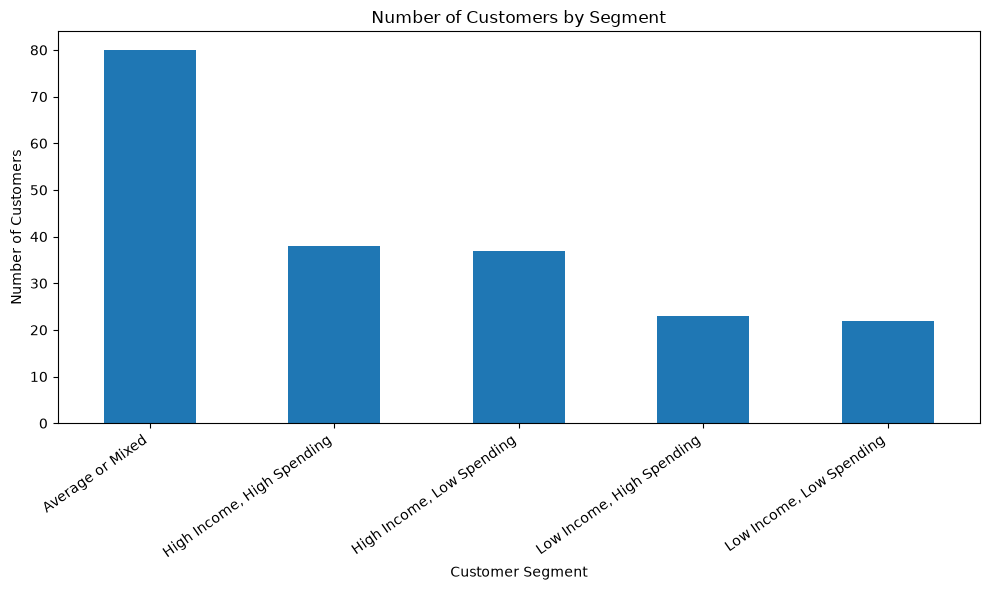

Project 2 results saved successfully!


In [9]:
import os
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

# Save customer segment counts
segment_counts.to_csv("outputs/customer_segment_counts.csv")

# Save gender analysis
gender_analysis.to_csv("outputs/gender_analysis.csv")

# Save customer segment chart
plt.figure(figsize=(10, 6))
segment_counts.plot(kind="bar", title="Number of Customers by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("outputs/customer_segments.png", dpi=300)
plt.show()

# Save the full dataset with customer segments
df.to_csv("outputs/customers_with_segments.csv", index=False)

print("Project 2 results saved successfully!")

In [10]:
report = """
CUSTOMER SEGMENTATION ANALYSIS REPORT

1. PROJECT OVERVIEW
Analyzed 200 customer records to understand customer demographics,
annual income, and spending behavior.

2. KEY FINDINGS
- Total customers: 200
- Average customer age: 38.85 years
- Average annual income: 60.56 (in thousands of dollars)
- Average spending score: 50.20 out of 100

3. CUSTOMER SEGMENTS
- Average or Mixed: 80 customers
- High Income, High Spending: 38 customers
- High Income, Low Spending: 37 customers
- Low Income, High Spending: 23 customers
- Low Income, Low Spending: 22 customers

4. BUSINESS RECOMMENDATIONS
- Test loyalty rewards for high-income, high-spending customers.
- Test targeted promotions for high-income, low-spending customers.
- Explore affordable offers for low-income customers.
- Analyze the mixed group further before making assumptions.

5. TOOLS USED
Python, Pandas, Matplotlib, Jupyter Notebook.

6. LIMITATIONS
These are rule-based customer segments using selected income
and spending thresholds. They are exploratory and do not prove
that customer characteristics cause spending behavior.
"""

with open(
    "outputs/customer_analysis_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("Customer analysis report saved successfully!")

Customer analysis report saved successfully!
